# Statistics on Unseen Studies

## Imports

In [1]:
import os
import sys
import time
import pickle
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.append('../src')
from zoo import TASKS, FAMILY, META, SEED, reg_models, clf_models, make_pipeline, grid_prefix, load_task, make_folds

warnings.filterwarnings('ignore')
sns.set_theme(style='ticks', context='notebook')

from sklearn.metrics import r2_score, f1_score, mean_absolute_error

## Load Results

In [2]:
zoo = pd.concat([pd.read_csv(f'../results/{t}__zoo_results.csv') for t in TASKS], ignore_index=True)
zoo['Score'] = zoo['Test_r2'].fillna(zoo['Test_f1'])
nested_results = {t: pickle.load(open(f'../results/nested/{t}.pkl', 'rb')) for t in TASKS}
zoo.shape

(98, 25)

## Helper Functions

In [3]:
def nemenyi_cd(k, n, alpha=0.05):
    # critical difference of average ranks (Nemenyi test)
    q = stats.studentized_range.ppf(1 - alpha, k, 1e6) / np.sqrt(2)
    return q * np.sqrt(k * (k + 1) / (6 * n))


def bootstrap_pair(a, b, rng, n_boot=4000):
    # a, b: per-study losses of two models; probability that the mean loss of a is lower than that of b
    n = len(a)
    w = rng.randint(0, n, (n_boot, n))
    d = a[w].mean(1) - b[w].mean(1)
    return float((d < 0).mean()), np.percentile(d, [2.5, 97.5]).tolist()

## Nested Scores and Rankings

In [4]:
summary = {}
for task, R in nested_results.items():
    clf, y, g = R['clf'], R['y'], R['groups']
    models = list(R['pred'])
    reps = sorted(set.intersection(*[set(R['pred'][m]) for m in models]))
    score = lambda yy, pp: f1_score(yy, np.nan_to_num(pp).astype(int), average='macro') if clf else r2_score(yy, pp)

    # random-split score against the pooled nested score of each model
    rows = []
    for m in models:
        s = [score(y, R['pred'][m][r]) for r in reps]
        z = zoo[(zoo['File'] == task) & (zoo['Model'] == m)].iloc[0]
        rows.append(dict(Model=m, Family=FAMILY[m], Random_test=z['Score'], Zoo_groupOOF=z['GroupOOF_score'],
                         Nested_mean=np.mean(s), Nested_sd=np.std(s), Nested_min=np.min(s), Nested_max=np.max(s)))
    table = pd.DataFrame(rows)
    table['Gap'] = table['Random_test'] - table['Nested_mean']
    res = dict(table=table, reps=reps)

    # per-study loss of every model, averaged over the repeats
    studies = np.unique(g)
    loss = {}
    for m in models:
        per_rep = []
        for r in reps:
            p = R['pred'][m][r]
            if clf:
                per_rep.append([np.mean(y[g == u] != np.nan_to_num(p[g == u]).astype(int)) for u in studies])
            else:
                per_rep.append([np.mean(np.abs(y[g == u] - p[g == u])) for u in studies])
        loss[m] = np.mean(per_rep, axis=0)
    loss = pd.DataFrame(loss, index=studies)

    # Friedman test over studies and Nemenyi critical difference
    fr = stats.friedmanchisquare(*[loss[m].values for m in models])
    ranks = loss.rank(axis=1).mean().sort_values()
    cd = nemenyi_cd(len(models), len(studies))
    res.update(friedman=(float(fr.statistic), float(fr.pvalue)), ranks=ranks, cd=float(cd), npapers=len(studies))
    res['fam_rank'] = ranks.groupby(lambda m: FAMILY[m]).mean().sort_values()

    # the same test on family means (no advantage for families with many members)
    fam_loss = loss.T.groupby(lambda m: FAMILY[m]).mean().T
    fr2 = stats.friedmanchisquare(*[fam_loss[c].values for c in fam_loss.columns])
    res['fam_friedman'] = (float(fr2.statistic), float(fr2.pvalue))
    res['fam_meanrank'] = fam_loss.rank(axis=1).mean().sort_values()

    # paired bootstrap of the best nested model against every other model
    rng = np.random.RandomState(0)
    best = table.loc[table['Nested_mean'].idxmax(), 'Model']
    res['best_nested'] = best
    res['boot'] = {m: bootstrap_pair(loss[best].values, loss[m].values, rng) for m in models if m != best}

    # share of model pairs that cannot be told apart
    rk = ranks.values
    pairs = list(itertools.combinations(range(len(rk)), 2))
    res['indist_frac'] = float(np.mean([abs(rk[i] - rk[j]) < cd for i, j in pairs]))

    # heavy-tailed load target: scores for joints of 25 kN or less and for studies without large specimens
    if not clf:
        heavy = []
        big = np.unique(g[y > 25])
        small = ~np.isin(g, big)
        for m in models:
            r2_le25, mae_le25, rmsle, r2_small = [], [], [], []
            for r in reps:
                p = R['pred'][m][r]
                k = y <= 25
                r2_le25.append(r2_score(y[k], p[k]))
                mae_le25.append(mean_absolute_error(y[k], p[k]))
                rmsle.append(np.sqrt(np.mean((np.log1p(np.clip(p, 0, None)) - np.log1p(y)) ** 2)))
                r2_small.append(r2_score(y[small], p[small]))
            heavy.append(dict(Model=m, R2_all=table.set_index('Model')['Nested_mean'][m], R2_le25=np.mean(r2_le25),
                              MAE_le25=np.mean(mae_le25), RMSLE=np.mean(rmsle), R2_papers_no_big=np.mean(r2_small)))
        res['heavy'] = pd.DataFrame(heavy)
        res['frac_gt25'] = float((y > 25).mean())
        res['big_papers'] = big.tolist()

    # stability of the permutation importances on held-out folds
    features = R['feat']
    stab, mean_imp = {}, {}
    for m in models:
        arr = np.vstack([R['imp'][m][r] for r in reps])
        arr = np.clip(np.nan_to_num(arr), 0, None)
        mean_imp[m] = arr.mean(0)
        rho = [stats.spearmanr(arr[i], arr[j])[0] for i, j in itertools.combinations(range(len(arr)), 2)
               if arr[i].std() > 0 and arr[j].std() > 0]
        top5 = [set(np.argsort(-a)[:5]) for a in arr]
        overlap = np.mean([len(a & b) / 5 for a, b in itertools.combinations(top5, 2)])
        stab[m] = dict(fold_rho=float(np.nanmean(rho)) if rho else np.nan, top5_overlap=float(overlap))
    res['stab'] = pd.DataFrame(stab).T

    # agreement between models: same family against different families
    imp_df = pd.DataFrame(mean_imp, index=features)
    rho = imp_df.corr(method='spearman')
    within, between = [], []
    for a, b in itertools.combinations(models, 2):
        (within if FAMILY[a] == FAMILY[b] else between).append(rho.loc[a, b])
    res['agree_unseen'] = (float(np.nanmean(within)), float(np.nanmean(between)))
    res['cons'] = (imp_df / imp_df.sum()).mean(axis=1).sort_values(ascending=False).head(8)
    summary[task] = res
list(summary)

['CFRP_CFRP__MaxLoad',
 'Composite_Composite__MaxLoad',
 'CFRP_CFRP__LSS',
 'Composite_Composite__LSS',
 'CFRP_CFRP__FailureMode',
 'Composite_Composite__FailureMode']

## Random Split Against Unseen Studies

In [5]:
comparison = []
for task, res in summary.items():
    t = res['table']
    comparison.append(dict(Task=task,
                           Best_random=t.loc[t['Random_test'].idxmax(), 'Model'], Random_score=t['Random_test'].max(),
                           Best_nested=res['best_nested'], Nested_score=t['Nested_mean'].max(),
                           Friedman_p=res['friedman'][1], Studies=res['npapers']))
comparison = pd.DataFrame(comparison)
comparison

,Task,Best_random,Random_score,Best_nested,Nested_score,Friedman_p,Studies
0,CFRP_CFRP__MaxLoad,LGBM,0.9613,ET,0.857039,1.121774e-26,31
1,Composite_Composite__MaxLoad,GB,0.9853,ET,0.852334,3.626661e-29,45
2,CFRP_CFRP__LSS,GB,0.9266,AB,-0.334918,4.072907e-14,28
3,Composite_Composite__LSS,RF,0.8378,LGBM,0.121291,1.217141e-19,42
4,CFRP_CFRP__FailureMode,LGBM,0.9321,RF,0.320193,1.249101e-02,29
5,Composite_Composite__FailureMode,GPC,0.9111,GNB,0.317306,6.791475e-02,42


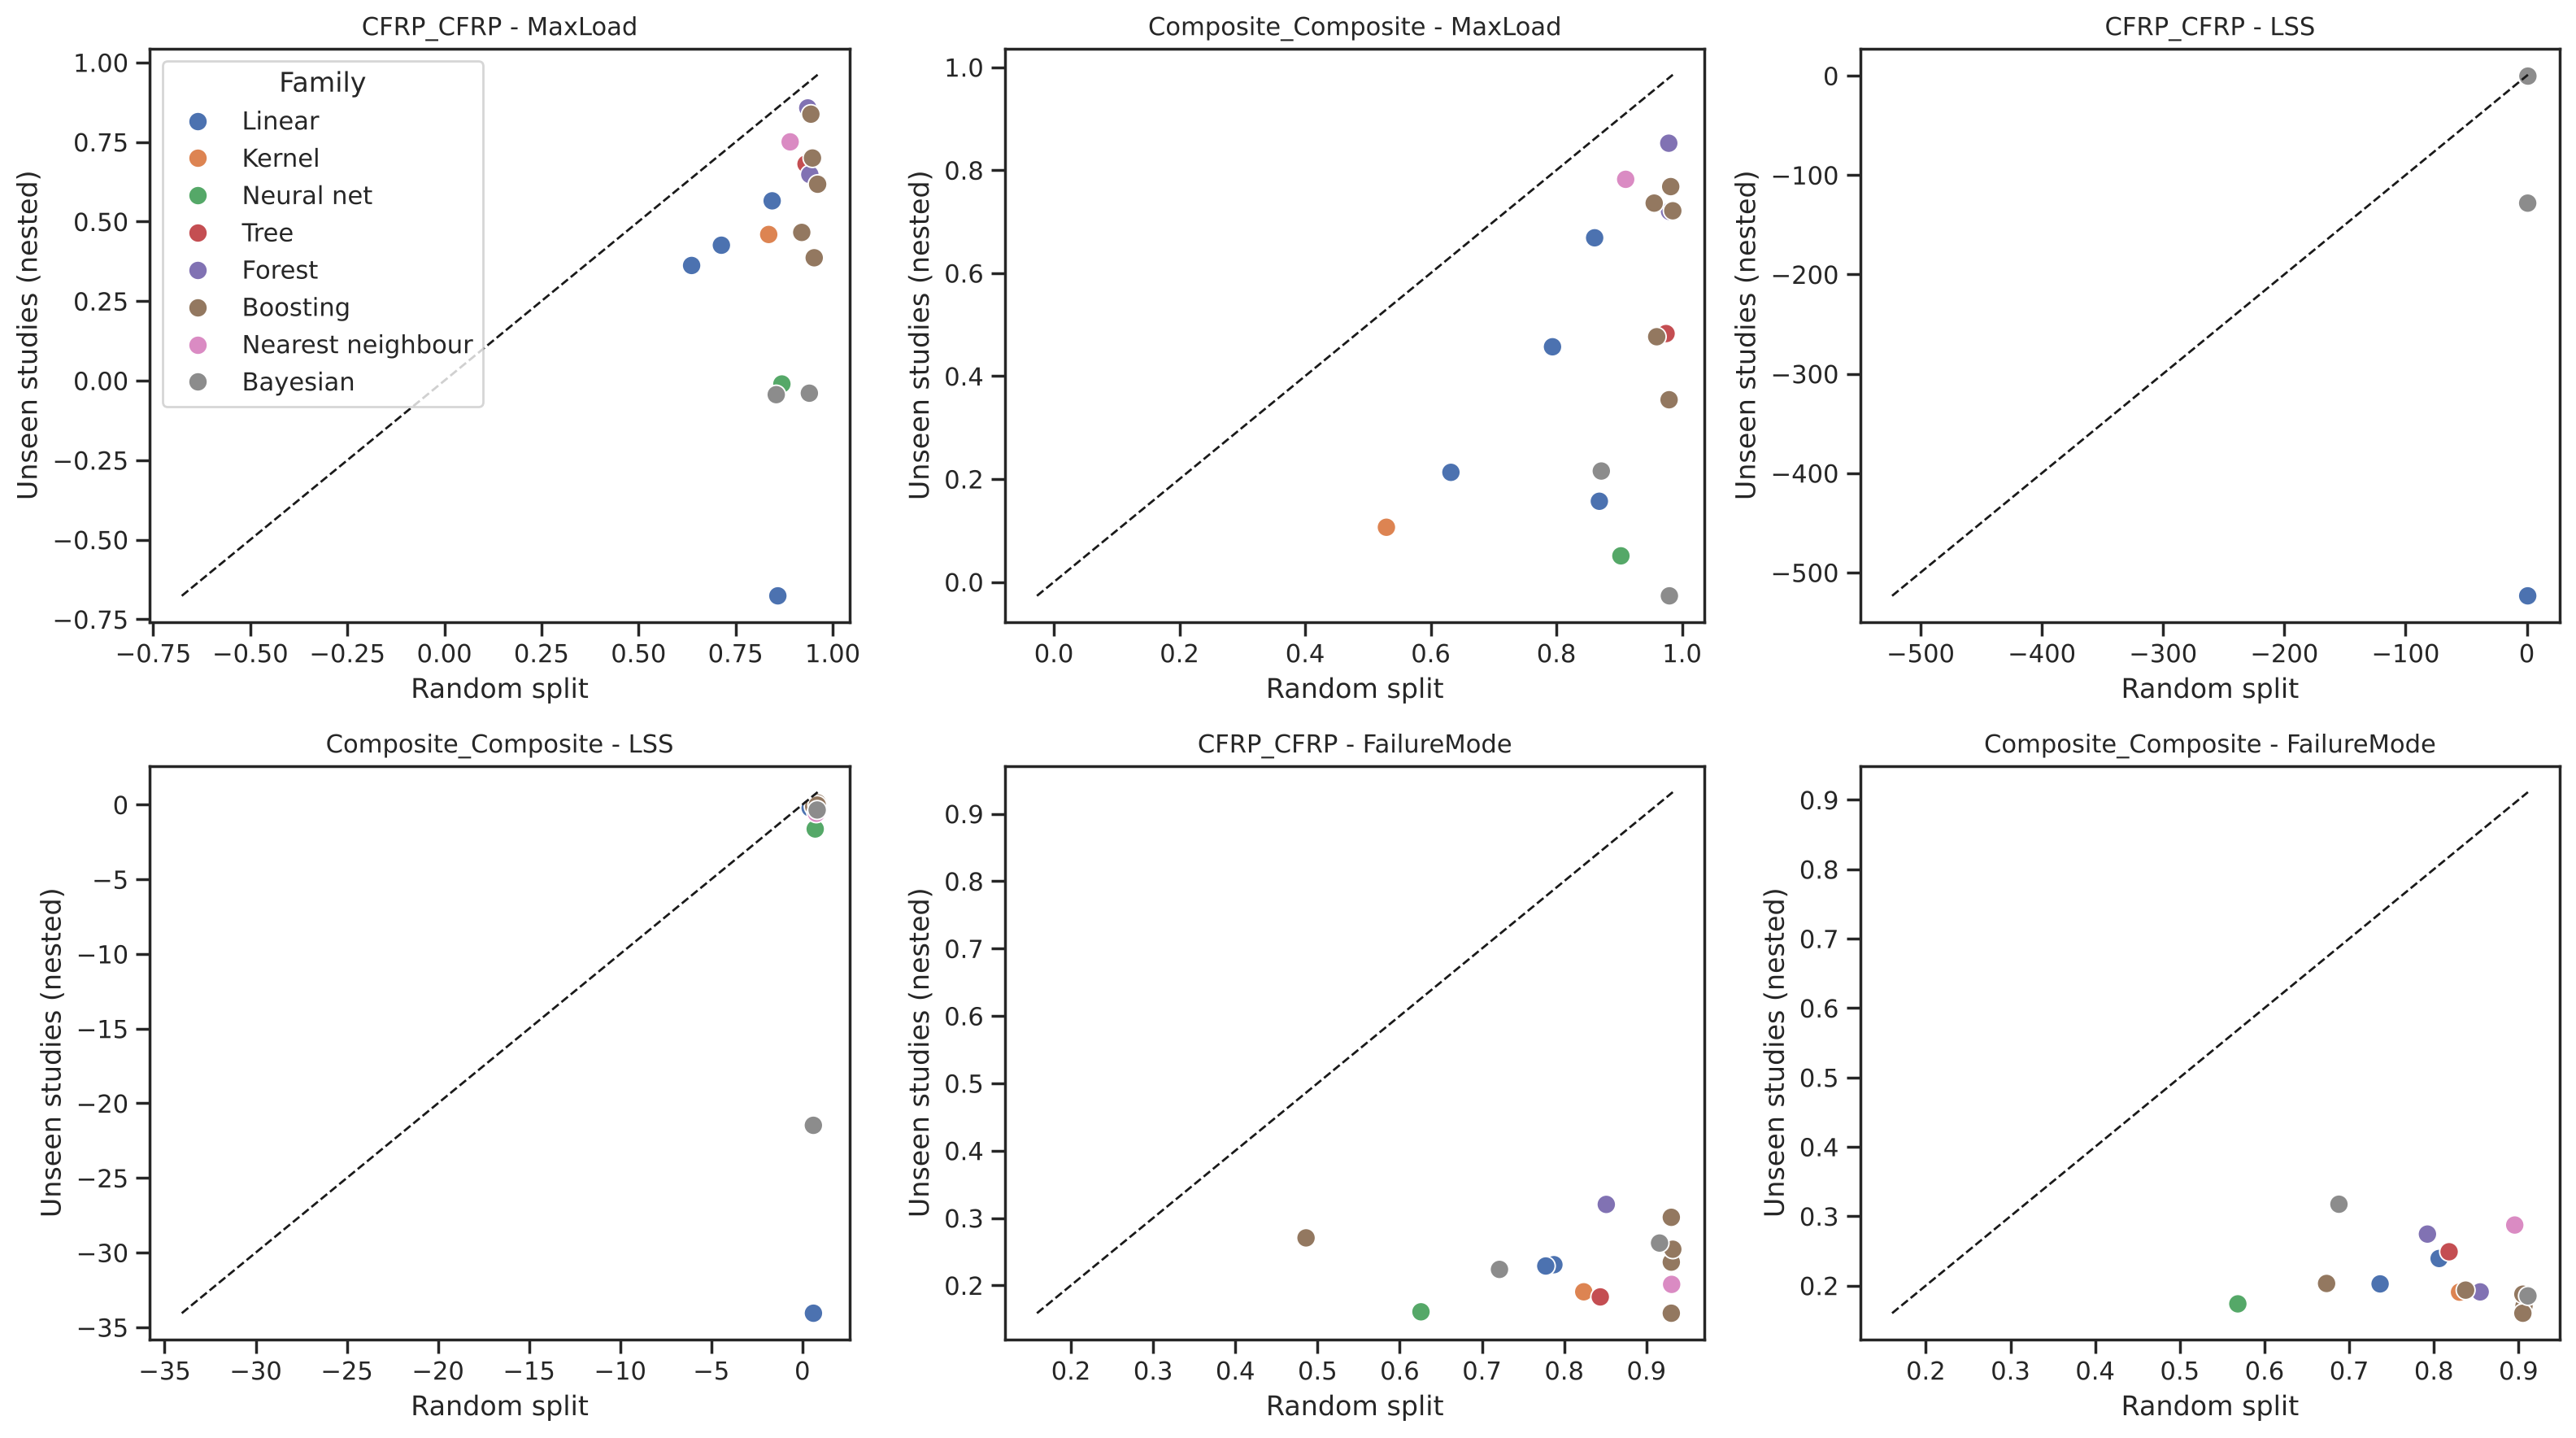

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (task, res) in zip(axes.ravel(), summary.items()):
    t = res['table']
    sns.scatterplot(data=t, x='Random_test', y='Nested_mean', hue='Family', s=70, ax=ax, legend=(task == list(summary)[0]))
    lim = [min(t['Random_test'].min(), t['Nested_mean'].min()), max(t['Random_test'].max(), t['Nested_mean'].max())]
    ax.plot(lim, lim, 'k--', lw=1)
    ax.set_title(task.replace('__', ' - '), fontsize=11)
    ax.set_xlabel('Random split'); ax.set_ylabel('Unseen studies (nested)')
plt.tight_layout()
plt.show()

## Baselines on the Same Folds

In [7]:
baselines = {}
for task, R in nested_results.items():
    y, clf = R['y'], R['clf']
    rows = []
    for r in sorted(R['fold']):
        fold_id = R['fold'][r]
        p_mean = np.zeros(len(y)); p_other = np.zeros(len(y))
        for k in range(5):
            tr, te = fold_id != k, fold_id == k
            if clf:
                majority = np.bincount(y[tr].astype(int)).argmax()
                p_mean[te] = majority; p_other[te] = majority
            else:
                p_mean[te] = y[tr].mean(); p_other[te] = np.median(y[tr])
        if clf:
            rows.append(dict(rep=r, score=f1_score(y, p_mean.astype(int), average='macro')))
        else:
            k25 = y <= 25
            rows.append(dict(rep=r, score=r2_score(y, p_mean), r2_le25=r2_score(y[k25], p_mean[k25]), mae_all=mean_absolute_error(y, p_other),
                             mae_le25_median=mean_absolute_error(y[k25], p_other[k25]), mae_le25_mean=mean_absolute_error(y[k25], p_mean[k25])))
    baselines[task] = pd.DataFrame(rows).mean().to_dict()
pd.DataFrame(baselines).T.round(3)

,rep,score,r2_le25,mae_all,mae_le25_median,mae_le25_mean
CFRP_CFRP__MaxLoad,1.0,-0.066,-2.360,11.216,4.462,7.990
Composite_Composite__MaxLoad,1.0,-0.044,-1.477,9.750,4.363,6.920
CFRP_CFRP__LSS,0.5,-0.246,-0.643,9.536,7.699,7.437
Composite_Composite__LSS,0.5,-0.162,-0.451,8.106,6.024,6.444
CFRP_CFRP__FailureMode,0.5,0.155,NaN,NaN,NaN,NaN
Composite_Composite__FailureMode,0.5,0.082,NaN,NaN,NaN,NaN


## Save

In [8]:
with open('../results/nested_statistics.pkl', 'wb') as fh:
    pickle.dump(summary, fh)
with open('../results/nested_baselines.pkl', 'wb') as fh:
    pickle.dump(baselines, fh)
comparison.to_csv('../results/random_vs_unseen_summary.csv', index=False)